# 05. Subtipos moleculares

O câncer de mama não é uma doença única. Os tumores são classificados em subtipos moleculares conforme três marcadores medidos na biópsia por um exame chamado imuno-histoquímica: o receptor de estrogênio (RE), o receptor de progesterona (RP) e a proteína HER2. A linhagem MDA-MB-231, usada no experimento do projeto, é um modelo do subtipo triplo-negativo.

A tabela abaixo mostra como os três marcadores definem os subtipos. Ela deixa claro que luminal e triplo-negativo são opostos: o tumor luminal tem receptor hormonal, e o triplo-negativo não tem nenhum dos três marcadores.

| Subtipo | Receptor hormonal (RE ou RP) | HER2 | Comportamento e tratamento |
|---|---|---|---|
| Luminal | positivo | negativo (luminal A e B) ou positivo (luminal B HER2) | Geralmente menos agressivo; responde à hormonioterapia |
| HER2 positivo (HER2 enriquecido) | negativo | positivo | Cresce mais rápido; tratado com medicamentos anti-HER2, como o trastuzumabe |
| Triplo-negativo | negativo | negativo | O mais agressivo; só pode ser tratado com quimioterapia convencional |

## Por que trabalhar com uma aproximação

O ideal seria contar diretamente o resultado da imuno-histoquímica de cada paciente. O problema é que nenhuma base pública brasileira traz esse resultado de forma completa. O RHC, o Painel de Oncologia e o SIM não têm o campo. O SISCAN tem um campo para os receptores hormonais (mas não para o HER2) nos laudos de histopatologia de mama. A célula abaixo mostra quantos laudos de câncer invasivo têm esse campo preenchido.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g, harmonizacao as h
from mama.config import FONTE_APAC
from mama.analises import base, rastreamento as ras, subtipos as sub

pd.set_option("display.max_columns", 20)
hp = ras.histopatologia()
preenchido = hp.receptor_hormonal.notna()
print(f"{len(hp):,} laudos de carcinoma invasivo de mama no SISCAN (2014 a 2024)")
print(f"{preenchido.sum():,} ({preenchido.mean():.1%}) têm o resultado do receptor hormonal")
rec = ras.receptor_hormonal(hp, ["regiao_res"])
rec["pct_laudos_com_resultado"] = (rec.n / hp.groupby("regiao_res").size().reindex(rec.regiao_res).to_numpy() * 100).round(1)
base.salvar_tabela(rec, "05_siscan_receptor_hormonal_regiao")
rec.rename(columns={"pct": "pct_receptor_positivo"})

133,484 laudos de carcinoma invasivo de mama no SISCAN (2014 a 2024)
8,927 (6.7%) têm o resultado do receptor hormonal


,regiao_res,n,eventos,pct_receptor_positivo,ic_inf,ic_sup,pct_laudos_com_resultado
0,Centro-Oeste,173,136,78.6,71.9,84.1,1.4
1,Nordeste,1939,1349,69.6,67.5,71.6,4.5
2,Norte,1406,994,70.7,68.3,73.0,16.4
3,Sudeste,3798,1645,43.3,41.7,44.9,9.7
4,Sul,1611,1292,80.2,78.2,82.1,5.4


Só cerca de 7% dos laudos têm o receptor registrado. Pior do que a quantidade é a seleção: entre os que têm, o percentual de receptor positivo vai de 43% no Sudeste a 80% no Sul. Essa diferença é grande demais para ser biológica, e indica que o exame só é registrado no SISCAN em situações particulares, diferentes de um lugar para outro. Com uma amostra tão pequena e tão selecionada, o SISCAN não serve para estimar a frequência dos subtipos no país.

Por isso, este caderno usa uma aproximação, também chamada de proxy: em vez do resultado do exame, usa o tratamento que o SUS autoriza, que depende diretamente do subtipo. É uma estimativa indireta, mas cobre todas as mulheres tratadas com quimioterapia ou hormonioterapia no SUS.

## Como a proxy funciona

Toda quimioterapia ou hormonioterapia oncológica no SUS precisa de uma APAC, uma autorização mensal que informa o procedimento exato. A tabela de procedimentos do SUS (SIGTAP) tem códigos específicos para cada situação, como "hormonioterapia do carcinoma de mama em estádio II" ou "poliquimioterapia do carcinoma de mama HER-2 positivo". Como cada subtipo tem um tratamento característico, o tratamento revela o subtipo:

| Se, ao longo do acompanhamento, a paciente recebeu... | o tumor tem... | e ela é classificada como |
|---|---|---|
| algum procedimento anti-HER2 | HER2 positivo | HER2 positivo |
| nenhum anti-HER2, mas alguma hormonioterapia ou procedimento descrito como "receptor positivo" | receptor hormonal positivo | Luminal |
| apenas quimioterapia convencional, sem hormonioterapia e sem anti-HER2 | provavelmente nenhum dos três marcadores | Provável triplo-negativo |

A lista exata dos códigos em cada grupo está em `src/mama/codigos.py`, e a classificação em `src/mama/fontes/apac.py`.

Esta classificação tem uma armadilha, e é por causa dela que o terceiro grupo se chama "provável". Muitas mulheres com tumor luminal fazem primeiro a quimioterapia e só depois começam a hormonioterapia. Se a observação terminar antes de a hormonioterapia começar, essa mulher terá recebido "apenas quimioterapia" e seria classificada, por engano, como triplo-negativa. Não é que o luminal seja considerado triplo-negativo; é que, sem tempo suficiente de acompanhamento, uma paciente luminal pode ainda não ter mostrado o tratamento que a identifica. A próxima seção mostra como esse problema foi tratado.

Há ainda duas limitações menores. Só entram mulheres tratadas com quimioterapia ou hormonioterapia pelo SUS. E tumores HER2 positivos que também têm receptor hormonal (luminal B HER2) ficam no grupo HER2.

## Por que usar uma coorte de casos novos

Se contássemos todas as mulheres em tratamento num ano, o grupo luminal ficaria inflado, porque a hormonioterapia dura de 5 a 10 anos e essas pacientes se acumulam. Por isso usamos uma coorte: mulheres cuja data do diagnóstico patológico, registrada na própria APAC, caiu em 2023, acompanhadas por todas as autorizações de 2023 e 2024.

Mesmo assim, o tempo de acompanhamento importa. Uma mulher luminal costuma fazer quimioterapia primeiro e só depois começar a hormonioterapia. Se ela foi diagnosticada em dezembro de 2023, talvez a hormonioterapia ainda não tenha começado até o fim de 2024, e ela seria contada, por engano, como provável triplo-negativa. A tabela abaixo testa essa hipótese.

In [2]:
coorte = base.apac()
print(f"{len(coorte):,} mulheres diagnosticadas em 2023 e tratadas com quimio ou hormonioterapia pelo SUS")
teste = sub.por_trimestre_de_diagnostico(coorte)
base.salvar_tabela(teste, "05_teste_seguimento_por_trimestre", index=True)
teste

50,399 mulheres diagnosticadas em 2023 e tratadas com quimio ou hormonioterapia pelo SUS


subtipo,Luminal (receptor hormonal +),HER2 positivo,Provável triplo-negativo
trimestre,,,
1,62.0,16.6,21.4
2,61.6,17.1,21.3
3,58.5,17.5,24.0
4,52.8,16.0,31.2


A armadilha aparece claramente. Entre as mulheres diagnosticadas no primeiro ou no segundo trimestre de 2023, cerca de 21% são classificadas como prováveis triplo-negativas. No quarto trimestre esse número sobe para 31%. Não há razão biológica para isso: são mulheres luminais diagnosticadas no fim do ano que ainda não tinham começado a hormonioterapia quando os dados terminaram.

Por isso, a partir daqui usamos apenas as mulheres diagnosticadas no primeiro semestre de 2023, que têm pelo menos 18 meses de acompanhamento.

In [3]:
apac = sub.com_seguimento_minimo(coorte)
apac["grupo_idade"] = h.grupo_50(apac.idade)
print(f"{len(apac):,} mulheres diagnosticadas entre janeiro e junho de 2023")
geral = apac.subtipo.value_counts(normalize=True).mul(100).round(1).reindex(c.SUBTIPO_ORDEM)
geral.rename("% das mulheres").to_frame()

25,535 mulheres diagnosticadas entre janeiro e junho de 2023


,% das mulheres
subtipo,
Luminal (receptor hormonal +),61.8
HER2 positivo,16.8
Provável triplo-negativo,21.3


No país, 62% dos tumores são luminais, 17% HER2 positivos e 21% prováveis triplo-negativos. Esses números são próximos dos de estudos brasileiros com imuno-histoquímica, que encontram cerca de 60% a 70% de luminais, 15% a 20% de HER2 positivos e 15% a 20% de triplo-negativos. O grupo triplo-negativo provavelmente ainda está um pouco superestimado, pelas razões discutidas acima. A proxy é, portanto, mais útil para comparar grupos entre si do que para dar a frequência exata.

## Subtipos por região

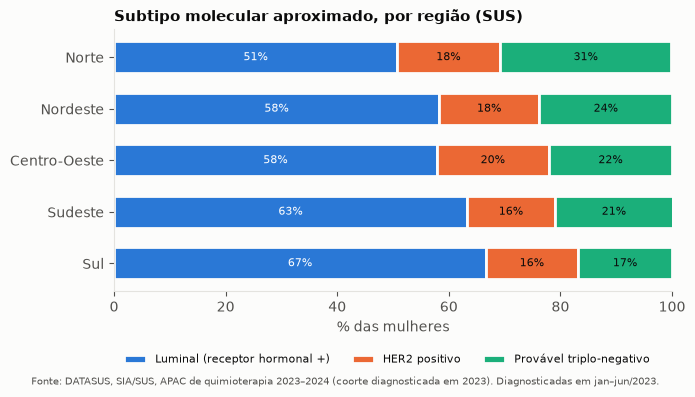

subtipo,Luminal (receptor hormonal +),HER2 positivo,Provável triplo-negativo
regiao_res,,,
Norte,50.7,18.4,30.8
Nordeste,58.2,18.0,23.8
Centro-Oeste,57.8,20.1,22.1
Sudeste,63.2,15.8,21.1
Sul,66.6,16.5,16.9


In [4]:
por_regiao = sub.distribuicao_subtipos(apac)
base.salvar_tabela(por_regiao, "05_subtipos_regiao", index=True)
fig, ax = g.empilhadas_100(por_regiao, "Subtipo molecular aproximado, por região (SUS)", "% das mulheres")
g.salvar(fig, "05_subtipos_regiao", FONTE_APAC + " Diagnosticadas em jan–jun/2023.")
plt.show()
por_regiao

A proporção de prováveis triplo-negativos cai de 31% no Norte para 17% no Sul, e a de luminais faz o caminho inverso, de 51% para 67%. O resultado reproduz o achado de Carvalho e colaboradores (2014) e de Simon e colaboradores (2019), citados no projeto, de que subtipos de pior prognóstico são mais frequentes no Norte. É uma segunda razão, além do acesso, para que o Norte tenha mais casos avançados e uma mortalidade que cresce mais rápido.

## Subtipos por idade

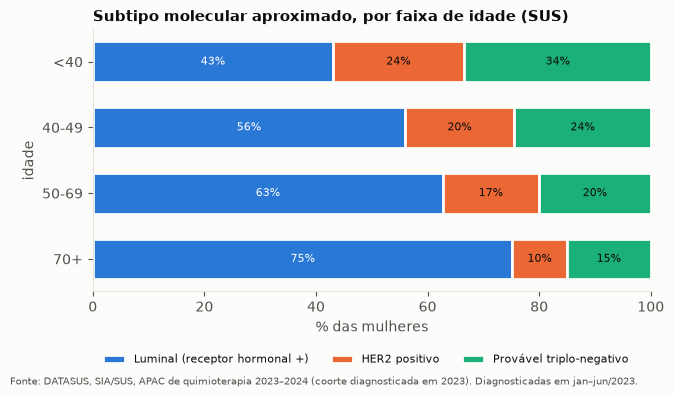

subtipo,Luminal (receptor hormonal +),HER2 positivo,Provável triplo-negativo
faixa_etaria,,,
<40,43.0,23.5,33.6
40-49,55.9,19.6,24.5
50-69,62.7,17.2,20.1
70+,75.2,9.7,15.1


subtipo,Luminal (receptor hormonal +),HER2 positivo,Provável triplo-negativo
grupo_idade,,,
50 anos ou mais,66.1,15.1,18.7
Menos de 50 anos,52.1,20.7,27.2


In [5]:
por_idade = sub.distribuicao_subtipos(apac, "faixa_etaria")
base.salvar_tabela(por_idade, "05_subtipos_faixa_etaria", index=True)
fig, ax = g.empilhadas_100(por_idade, "Subtipo molecular aproximado, por faixa de idade (SUS)", "% das mulheres")
ax.set_ylabel("idade")
g.salvar(fig, "05_subtipos_idade", FONTE_APAC + " Diagnosticadas em jan–jun/2023.")
plt.show()
display(por_idade)
sub.distribuicao_subtipos(apac, "grupo_idade")

A idade é o fator que mais muda a composição dos subtipos. Entre mulheres com menos de 40 anos, só 43% dos tumores são luminais, e um terço é provável triplo-negativo. Acima dos 70, três em cada quatro são luminais. Separando em dois grupos, abaixo dos 50 anos o triplo-negativo provável chega a 27%, contra 19% a partir dos 50.

Esse resultado ajuda a explicar o que os cadernos 04 e 11 mostraram: mulheres jovens chegam com doença mais avançada e são o grupo em que a mortalidade mais cresce. Além de estarem fora do rastreamento, elas têm com mais frequência tumores agressivos, que crescem rápido entre um exame e outro.

## Subtipos por raça/cor

Assim como no caderno 04, a comparação é feita dentro de cada região, para não confundir o efeito da raça/cor com o da geografia.

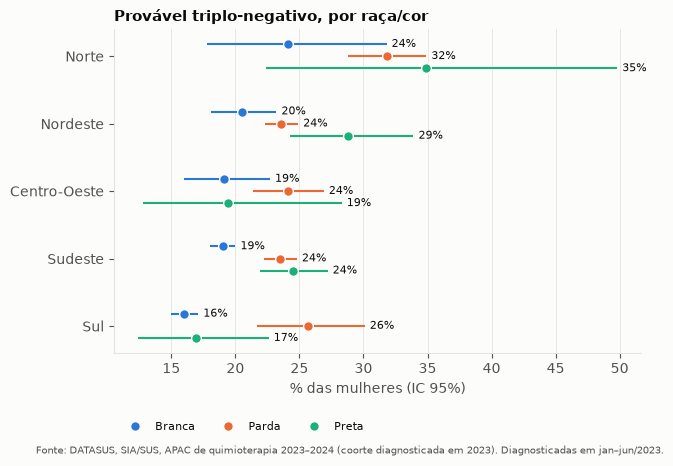

,raca_cor,n,eventos,pct,ic_inf,ic_sup
0,Amarela,684,176,25.7,22.6,29.1
1,Branca,12336,2222,18.0,17.3,18.7
2,Indígena,3,3,100.0,43.8,100.0
3,Parda,10659,2596,24.4,23.5,25.2
4,Preta,1681,410,24.4,22.4,26.5
5,Sem informação,172,40,23.3,17.6,30.1


In [6]:
t = sub.triplo_negativo_por(apac[apac.raca_cor.isin(["Branca", "Parda", "Preta"])], ["regiao_res", "raca_cor"])
base.salvar_tabela(t, "05_triplo_negativo_regiao_raca")
fig, ax = g.pontos_ic(t, "regiao_res", "raca_cor", "Provável triplo-negativo, por raça/cor",
                      "% das mulheres (IC 95%)", ordem_cat=c.REGIOES, ordem_grupo=["Branca", "Parda", "Preta"],
                      figsize=(6.8, 4.2))
g.salvar(fig, "05_triplo_negativo_raca", FONTE_APAC + " Diagnosticadas em jan–jun/2023.")
plt.show()
sub.triplo_negativo_por(apac, ["raca_cor"])

No país, 24% das mulheres pardas e pretas têm provável triplo-negativo, contra 18% das brancas. A diferença aparece em quase todas as regiões, e é maior no Norte e no Nordeste. Isso é coerente com a literatura internacional, que encontra mais triplo-negativo em mulheres de ascendência africana. Aqui vale lembrar o que foi dito no caderno 02: raça/cor é autodeclarada e não mede ancestralidade genética, então o dado indica uma associação, não uma causa.

## Subtipos por estado

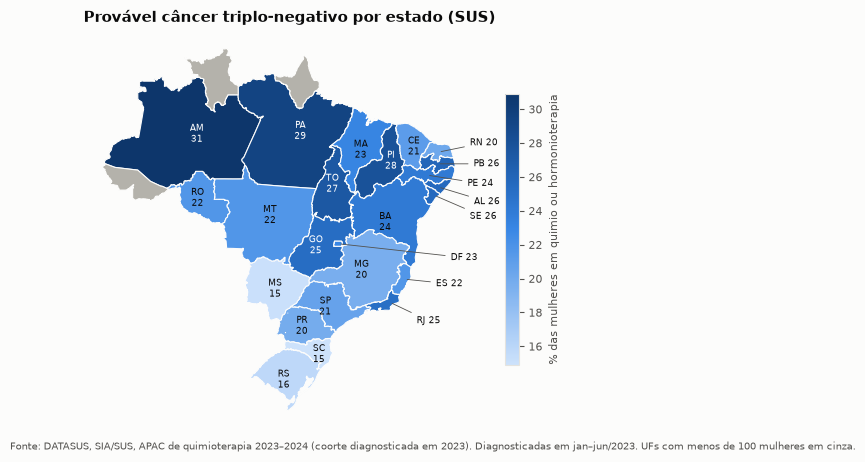

In [7]:
por_uf = sub.triplo_negativo_por(apac, ["uf_res"])
por_uf = por_uf[por_uf.n >= 100]
base.salvar_tabela(por_uf, "05_triplo_negativo_uf")
fig, ax = g.mapa_uf(por_uf.set_index("uf_res").pct, "Provável câncer triplo-negativo por estado (SUS)",
                    "% das mulheres em quimio ou hormonioterapia")
g.salvar(fig, "05_mapa_triplo_negativo_uf", FONTE_APAC + " Diagnosticadas em jan–jun/2023. UFs com menos de 100 mulheres em cinza.")
plt.show()

O mapa confirma o padrão regional, com os estados do Norte e parte do Nordeste mais escuros. Estados com menos de 100 mulheres na coorte ficam em cinza, porque a proporção seria instável.

## Subtipo e estádio

In [8]:
est_sub = sub.estadio_por_subtipo(apac)
base.salvar_tabela(est_sub, "05_estadio_avancado_por_subtipo")
est_sub

,subtipo,n,eventos,pct,ic_inf,ic_sup
0,HER2 positivo,4302,3076,71.5,70.1,72.8
1,Luminal (receptor hormonal +),15786,7230,45.8,45.0,46.6
2,Provável triplo-negativo,5447,3995,73.3,72.2,74.5


Entre as mulheres com tumores HER2 positivos ou prováveis triplo-negativos, mais de 70% estão em estádio III ou IV, contra 46% nas luminais. Esses percentuais são mais altos do que os do caderno 04, por dois motivos. O primeiro é que a coorte só inclui mulheres em quimioterapia ou hormonioterapia, e mulheres com tumores pequenos tratados apenas com cirurgia ficam de fora. O segundo é que o estádio da APAC é o informado para autorizar o tratamento, e não o estadiamento clínico do diagnóstico. Por isso, esses números servem para comparar os subtipos entre si, e não para comparar com o RHC.

## Outras características do tumor: grau e tamanho

Os laudos do SISCAN, mesmo sem o receptor, registram com frequência duas características ligadas à agressividade: o grau histológico, de I (células parecidas com as normais, crescimento lento) a III (células muito alteradas, crescimento rápido), e o tamanho do tumor no momento da biópsia.

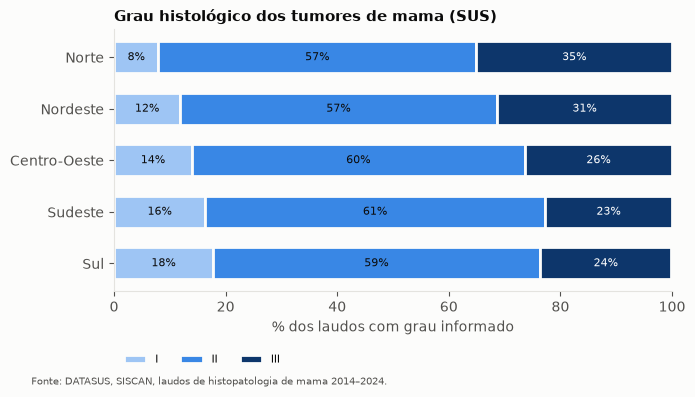

grau_histologico,I,II,III
regiao_res,,,
Norte,7.9,57.0,35.1
Nordeste,11.8,56.8,31.4
Centro-Oeste,13.9,59.7,26.4
Sudeste,16.3,60.9,22.8
Sul,17.7,58.6,23.6


tamanho_tumor,Menos de 2 cm,2 a 5 cm,Mais de 5 cm
regiao_res,,,
Norte,24.8,50.9,24.3
Nordeste,36.3,44.7,19.0
Centro-Oeste,25.4,48.7,25.9
Sudeste,36.5,48.8,14.6
Sul,30.9,44.3,24.8


In [9]:
grau = base.distribuicao(hp[hp.grau_histologico.notna()], "grau_histologico", ordem=["I", "II", "III"])
tamanho = base.distribuicao(hp[hp.tamanho_tumor.notna()], "tamanho_tumor", ordem=["Menos de 2 cm", "2 a 5 cm", "Mais de 5 cm"])
base.salvar_tabela(grau, "05_siscan_grau_histologico_regiao", index=True)
base.salvar_tabela(tamanho, "05_siscan_tamanho_tumor_regiao", index=True)
cores_grau = {"I": "#9ec5f4", "II": "#3987e5", "III": "#0d366b"}
fig, ax = g.empilhadas_100(grau, "Grau histológico dos tumores de mama (SUS)", "% dos laudos com grau informado", cores=cores_grau)
g.salvar(fig, "05_siscan_grau_histologico", "DATASUS, SISCAN, laudos de histopatologia de mama 2014–2024.")
plt.show()
display(grau)
tamanho

O padrão regional se repete. No Norte, 35% dos tumores são de grau III, contra cerca de 23% no Sul e no Sudeste, e um em cada quatro tem mais de 5 cm na biópsia, contra 15% no Sudeste. Tumores de grau III são mais frequentes entre os triplo-negativos e HER2 positivos, e tumores grandes indicam descoberta tardia. Os dois resultados são coerentes com a proxy de subtipo e com o caderno 04.

## O que levar para o TCC

Nenhuma base pública traz o resultado completo da imuno-histoquímica; o SISCAN registra o receptor hormonal em só 7% dos laudos, de forma muito seletiva. Por isso o subtipo foi aproximado pelo tratamento autorizado no SUS. Com essa proxy, cerca de 62% dos tumores são luminais, 17% HER2 positivos e 21% prováveis triplo-negativos. O triplo-negativo, subtipo modelado pela linhagem MDA-MB-231 do projeto, é mais frequente no Norte (31%), em mulheres com menos de 40 anos (34%) e em mulheres pretas e pardas. Ao citar esses números, é preciso descrever a proxy e suas limitações, e apresentá-los como estimativas.